In [26]:
import os 
from tqdm import tqdm 
import tensorflow as tf
import keras
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
import numpy as np

In [27]:
DATA_PATH_TRAINING = ('../data/Training/')

x = []
y = []
counter = 0

classes = os.listdir(DATA_PATH_TRAINING)
print(classes)

['glioma', 'meningioma', 'notumor', 'pituitary']


In [28]:
img_rows, img_cols = 299, 299
print(img_rows, img_cols)

299 299


## Preprocessing

### Training

In [ ]:
for class_name in sorted(os.listdir(DATA_PATH_TRAINING)):
    print(counter, class_name)
    for fileName in tqdm(os.listdir(f"{DATA_PATH_TRAINING}{class_name}")):
        path = f"{DATA_PATH_TRAINING}{class_name}/{fileName}"
        label = counter

        image = tf.keras.preprocessing.image.load_img(path, target_size=(img_rows, img_cols), color_mode='grayscale')
        image = tf.keras.preprocessing.image.img_to_array(image)

        x.append(image)
        y.append(label)

    counter += 1

100%|██████████| 1400/1400 [00:04<00:00, 337.01it/s]


In [30]:
x = np.array(x)
y = np.array(y)

x = x.astype('float32') / 255.0

### Testing

In [ ]:
DATA_PATH_TESTING = ('../data/Testing/')

X_test = []
y_test = []
counter_test = 0

classes_test = os.listdir(DATA_PATH_TESTING)
print(classes_test)

['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:
classes = sorted(os.listdir(DATA_PATH_TRAINING))
classes_test = sorted(os.listdir(DATA_PATH_TESTING))

print(classes)
print(classes_test)

In [ ]:
for class_name_test in sorted(os.listdir(DATA_PATH_TESTING)):
    print(counter_test, class_name_test)
    for fileName_test in tqdm(os.listdir(f"{DATA_PATH_TESTING}{class_name_test}")):
        path_test = f"{DATA_PATH_TESTING}{class_name_test}/{fileName_test}"
        label_test = counter

        image = tf.keras.preprocessing.image.load_img(path_test, target_size=(img_rows, img_cols), color_mode='grayscale')
        image = tf.keras.preprocessing.image.img_to_array(image)

        X_test.append(image)
        y_test.append(label_test)

    counter_test += 1

100%|██████████| 400/400 [00:01<00:00, 202.65it/s]


In [33]:
X_test = np.array(X_test)
y_test = np.array(y_test)

X_test = X_test.astype('float32') / 255.0

y_test = keras.utils.to_categorical(y_test, num_classes=4)

## Split Data Training & Val (80 : 20)

In [34]:
X_train, X_val, y_train, y_val = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

# Ubah label jadi One Hot Encoder
y_train = keras.utils.to_categorical(y_train, num_classes=4)
y_val = keras.utils.to_categorical(y_val, num_classes=4)

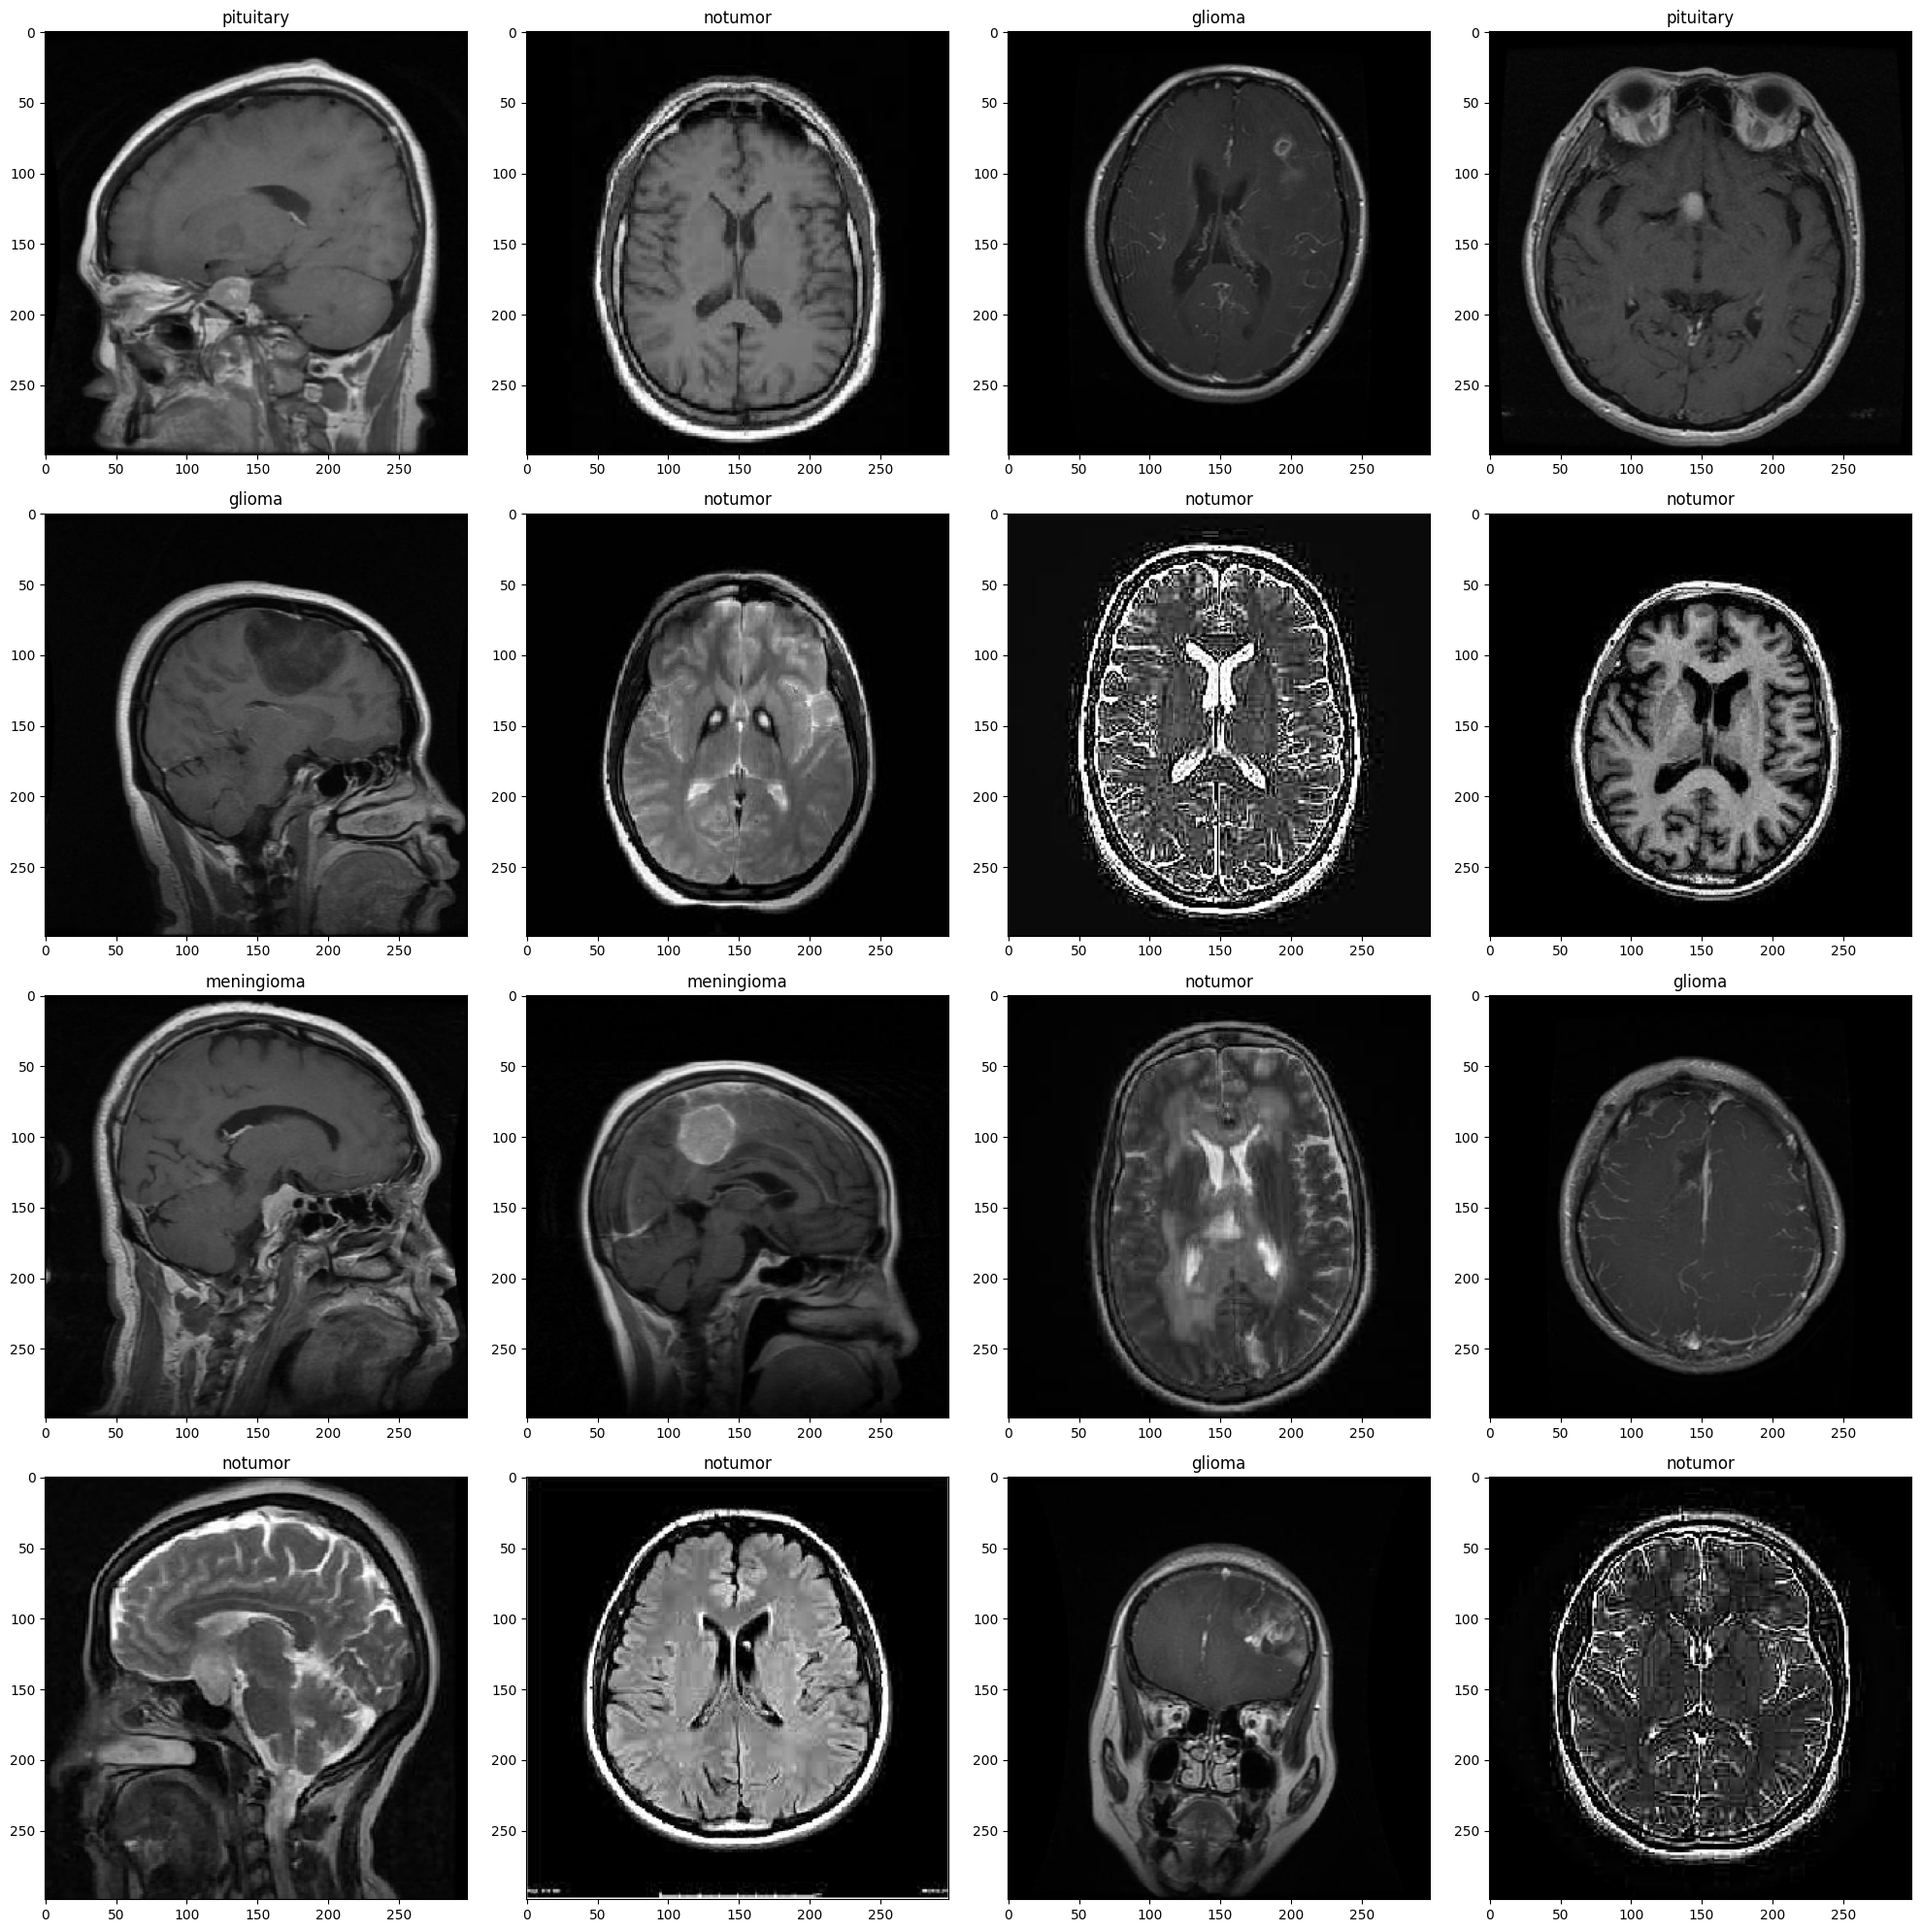

In [35]:
plt.figure(figsize=(20,20))

for i in range(16):
    img = X_train[i]
    label = classes[np.argmax(y_train[i])]

    plt.subplot(4, 4, i+1)
    if img.shape[-1] == 1:
        plt.imshow(img.squeeze(), cmap='gray')
    else:
        plt.imshow(img)
    
    plt.title(label, fontsize=12)

plt.tight_layout()
plt.show()

## Deep Learning Model

In [ ]:
base_model = tf.keras.applications.Xception(
    include_top=False, 
    weights='imagenet', 
    input_shape=(img_rows, img_cols, 3), 
    pooling='max'
)

base_model.trainable = False

model = keras.Sequential([
    keras.layers.Input(shape=(img_rows, img_cols, 1)),
    keras.layers.Rescaling(2.00, offset=-1),
    keras.layers.Lambda(lambda t: tf.repeat(t, 3, axis=-1)), ## --> ubah dari layer grayscale yang 1, jadi 3
    base_model,
    keras.layers.Flatten(),
    keras.layers.Dropout(rate=0.3),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dropout(rate=0.25),
    keras.layers.Dense(4, activation='softmax')
])

print(model.summary())

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling_2 (Rescaling)     (None, 299, 299, 1)       0         
                                                                 
 lambda_2 (Lambda)           (None, 299, 299, 3)       0         
                                                                 
 xception (Functional)       (None, 2048)              20861480  
                                                                 
 flatten_2 (Flatten)         (None, 2048)              0         
                                                                 
 dropout_4 (Dropout)         (None, 2048)              0         
                                                                 
 dense_4 (Dense)             (None, 128)               262272    
                                                                 
 dropout_5 (Dropout)         (None, 128)              

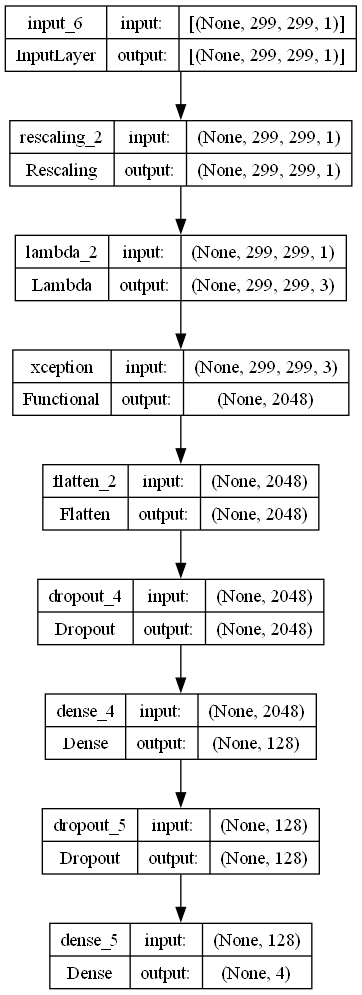

In [37]:
tf.keras.utils.plot_model(model, show_shapes=True)

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience = 3,
    restore_best_weights=True
)

checkpoint = keras.callbacks.ModelCheckpoint(
    filepath='../models/brain_tumor_model_xception_version1.keras',
    monitor='val_loss',
    save_best_only=True,
    mode='min'
)

history = model.fit(
    X_train, y_train, batch_size=32, validation_data=(X_val, y_val), epochs=20, callbacks=[early_stopping, checkpoint]
)

Epoch 1/20
140/140 [==============================] - 4978s 35s/step - loss: 0.4201 - accuracy: 0.8625 - val_loss: 8.9079 - val_accuracy: 0.2500
Epoch 2/20
 21/140 [===>..........................] - ETA: 1:15:23 - loss: 0.2840 - accuracy: 0.9182

## Model Prediction & Evaluation

In [ ]:
from sklearn.utils import shuffle

X_test, y_test = shuffle(
    X_test, y_test, random_state=42
)

In [ ]:
score = model.evaluate(X_test, y_test)
print(f"Test Loss = {score[0]}")
print(f"Test Accuracy : {score[1]}")

In [ ]:
predictions = model.predict(X_test)
predicted_labels = np.argmax(predictions, axis=1)
actual_labels = np.argmax(y_test, axis=1)

plt.figure(figsize=(10,6))

for i in range(9): 
    ax = plt.subplot(3, 3, i+1)
    ax.imshow(X_test[i], cmap='gray')
    ax.axis('off')
    ax.set_title(f'Actual : {classes[actual_labels[i]]}\nPredicted : {classes[predicted_labels[i]]}', fontsize=10)

plt.tight_layout()

for i in range(9): 
    print(f'Actual : {classes[actual_labels[i]]}\t\t | Predicted : {classes[predicted_labels[i]]}')

In [ ]:
plt.figure(figsize=(18, 6))

# Accuracy Plotting
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.legend()

# Loss Plotting
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()

plt.show()

## Saved Model

In [ ]:
# from pathlib import Path

# PROJECT_ROOT = Path.cwd().parent
# MODEL_PATH = PROJECT_ROOT / "models" / "brain_tumor_model_xception_stage1.keras"

# model_testing = tf.keras.models.load_model(MODEL_PATH)

## Confusion Matrix

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

class_names = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

y_true = np.argmax(y_test, axis=1)

y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3]
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - External Testing")
plt.show()

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

In [ ]:
wrong_index = np.where(predicted_labels != actual_labels)[0]
print('Jumlah prediksi salah : ', len(wrong_index))

In [ ]:
plt.figure(figsize=(12, 10))

for i, idx in enumerate(wrong_index[:9]):
  ax = plt.subplot(3, 3, i+1)
  ax.imshow(X_test[idx].squeeze(), cmap='gray')
  ax.set_title(f'Actual : {classes[actual_labels[idx]]}\nPredicted : {classes[predicted_labels[idx]]}')
  ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(
    actual_labels,
    predicted_labels,
    target_names=classes
))

print(confusion_matrix(actual_labels, predicted_labels))

## Fine Tuning

In [ ]:
import tensorflow as tf
import keras

In [ ]:
model_ft = keras.models.load_model('../models/brain_tumor_model_xception_version1.keras')

In [ ]:
for layer in model_ft.layers:
  print(layer.name, type(layer).__name__)

In [ ]:
base_model_ft = model_ft.get_layer('xception')
base_model.trainable = True

In [ ]:
for layer in base_model.layers[:-20]:
    layer.trainable = False

In [ ]:
model_ft.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print(model_ft.summary())

In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

checkpoint = keras.callbacks.ModelCheckpoint(
    filepath='../models/brain_tumor_model_xception_finetuned.keras',
    monitor='val_loss',
    save_best_only=True,
    mode='min'
)

# Ensure tf is in the global scope so the deserialized Lambda layer can access it
history_finetune = model_ft.fit(
    X_train,
    y_train,
    batch_size=8,
    validation_data=(X_val, y_val),
    epochs=10,
    callbacks=[early_stopping, checkpoint]
)

In [ ]:
test_loss_ft, test_accuracy_ft = model_ft.evaluate(X_test, y_test)

print("Test Loss:", test_loss_ft)
print("Test Accuracy:", test_accuracy_ft)